In [1182]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor,DecisionTreeClassifier
from sklearn.metrics import r2_score,mean_absolute_error,mean_absolute_percentage_error,mean_squared_error

# Load Data

In [1183]:
df = pd.read_csv("/content/Real estate.csv")
df

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1
...,...,...,...,...,...,...,...,...
409,410,2013.000,13.7,4082.01500,0,24.94155,121.50381,15.4
410,411,2012.667,5.6,90.45606,9,24.97433,121.54310,50.0
411,412,2013.250,18.8,390.96960,7,24.97923,121.53986,40.6
412,413,2013.000,8.1,104.81010,5,24.96674,121.54067,52.5


# Data Properties

In [1184]:
df.shape

(414, 8)

In [1185]:
df.columns

Index(['No', 'X1 transaction date', 'X2 house age',
       'X3 distance to the nearest MRT station',
       'X4 number of convenience stores', 'X5 latitude', 'X6 longitude',
       'Y house price of unit area'],
      dtype='object')

In [1186]:
df.isna().sum()

,0
No,0
X1 transaction date,0
X2 house age,0
X3 distance to the nearest MRT station,0
X4 number of convenience stores,0
X5 latitude,0
X6 longitude,0
Y house price of unit area,0


In [1187]:
df.dtypes

,0
No,int64
X1 transaction date,float64
X2 house age,float64
X3 distance to the nearest MRT station,float64
X4 number of convenience stores,int64
X5 latitude,float64
X6 longitude,float64
Y house price of unit area,float64


# Feature Selection

In [1188]:
corr = df.corr(numeric_only=True)
corr

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
No,1.000000,-0.048658,-0.032808,-0.013573,-0.012699,-0.010110,-0.011059,-0.028587
X1 transaction date,-0.048658,1.000000,0.017549,0.060880,0.009635,0.035058,-0.041082,0.087491
X2 house age,-0.032808,0.017549,1.000000,0.025622,0.049593,0.054420,-0.048520,-0.210567
X3 distance to the nearest MRT station,-0.013573,0.060880,0.025622,1.000000,-0.602519,-0.591067,-0.806317,-0.673613
X4 number of convenience stores,-0.012699,0.009635,0.049593,-0.602519,1.000000,0.444143,0.449099,0.571005
X5 latitude,-0.010110,0.035058,0.054420,-0.591067,0.444143,1.000000,0.412924,0.546307
X6 longitude,-0.011059,-0.041082,-0.048520,-0.806317,0.449099,0.412924,1.000000,0.523287
Y house price of unit area,-0.028587,0.087491,-0.210567,-0.673613,0.571005,0.546307,0.523287,1.000000


<Axes: >

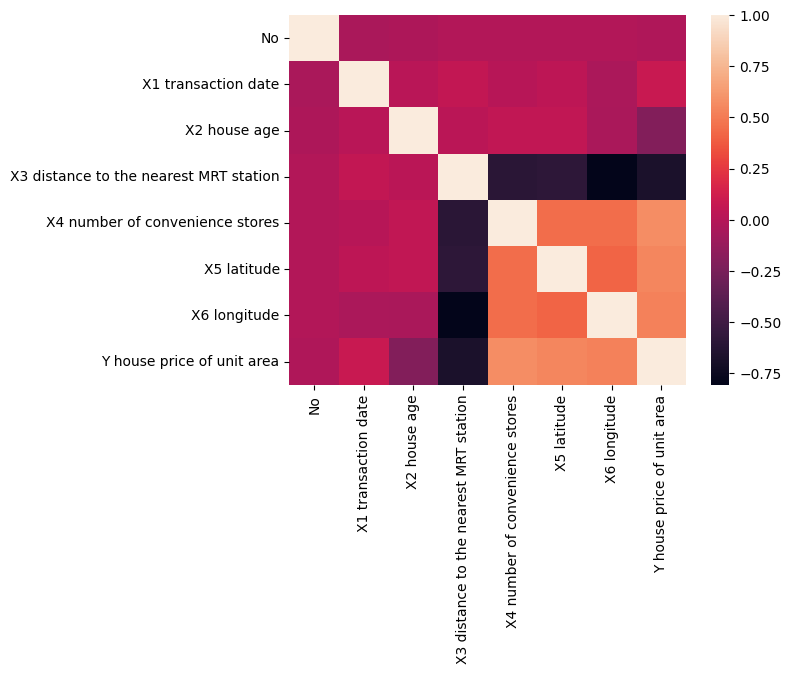

In [1189]:
sns.heatmap(corr)

# Drop unwanted Columns

In [1190]:
df = df.drop(['No','X1 transaction date'],axis=1)

# Outliers Handling


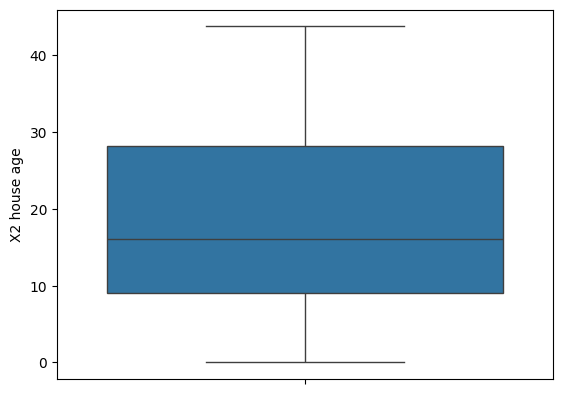

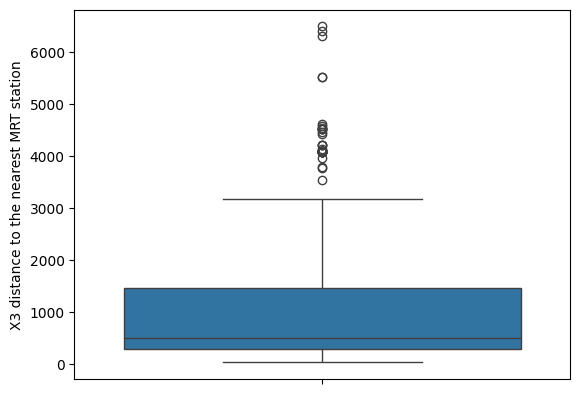

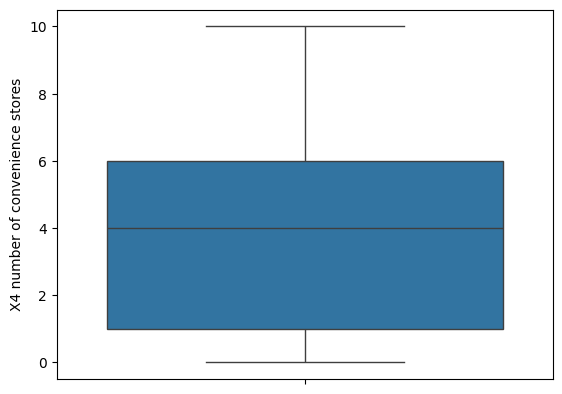

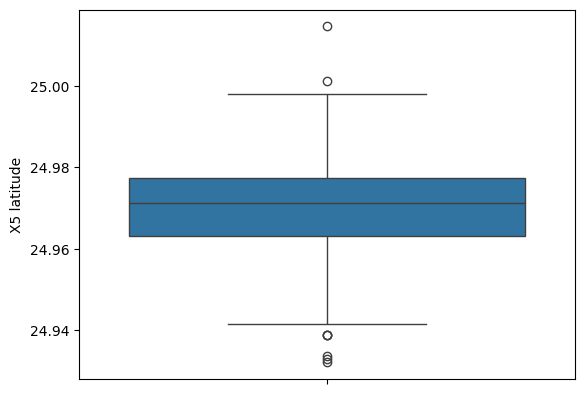

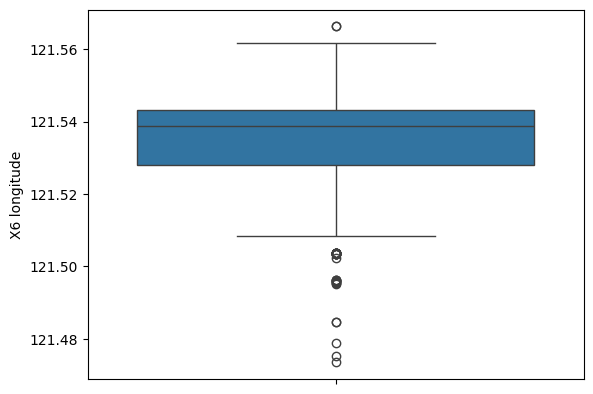

In [1191]:
for i in df.columns[:-1]:
  sns.boxplot(data=df,y=i)
  plt.show()

In [1192]:
# for i in df.columns[:-1]:
#   q1 = df[i].quantile(.25)
#   q3 = df[i].quantile(.75)

#   iqr = q3 - q1
#   lower = q1 - 1.5 * iqr
#   upper = q3 + 1.5 * iqr
#   # Correctly filter the DataFrame in-place to keep rows within bounds
#   df = df[(df[i] >= lower) & (df[i] <= upper)]

exclude = ["No", "Y house price of unit area"]

columns = df.select_dtypes(include="number").columns.drop(
    exclude, errors="ignore"
)

mask = pd.Series(True, index=df.index)

for col in columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)

    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask &= df[col].between(lower, upper)

df = df.loc[mask].copy()

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Removed rows:", len(df) - len(df_clean))

Original rows: 414
Cleaned rows: 374
Removed rows: 40


In [1193]:
df

,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,32.0,84.87882,10,24.98298,121.54024,37.9
1,19.5,306.59470,9,24.98034,121.53951,42.2
2,13.3,561.98450,5,24.98746,121.54391,47.3
3,13.3,561.98450,5,24.98746,121.54391,54.8
4,5.0,390.56840,5,24.97937,121.54245,43.1
...,...,...,...,...,...,...
409,13.7,4082.01500,0,24.94155,121.50381,15.4
410,5.6,90.45606,9,24.97433,121.54310,50.0
411,18.8,390.96960,7,24.97923,121.53986,40.6
412,8.1,104.81010,5,24.96674,121.54067,52.5


#regression Plot

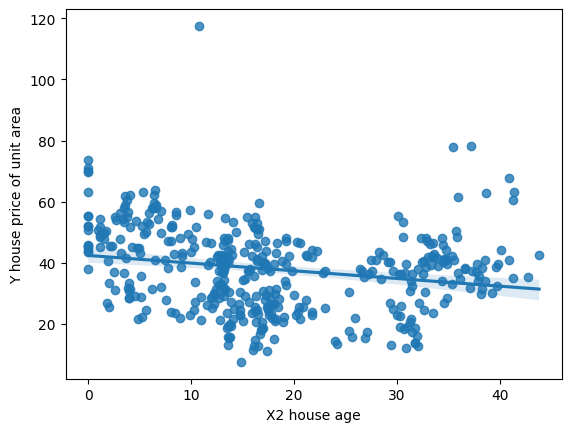

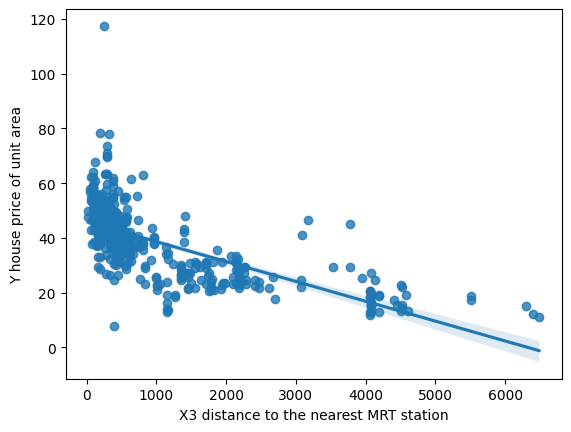

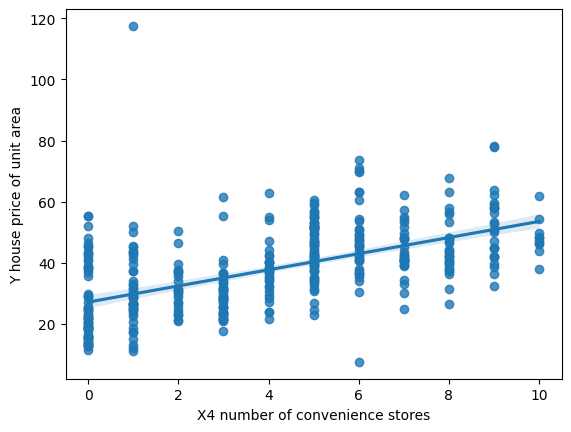

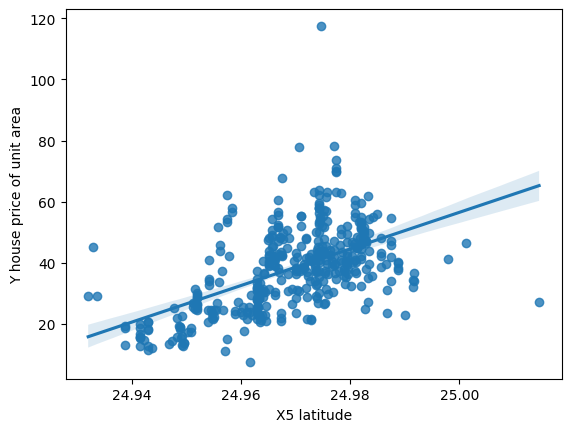

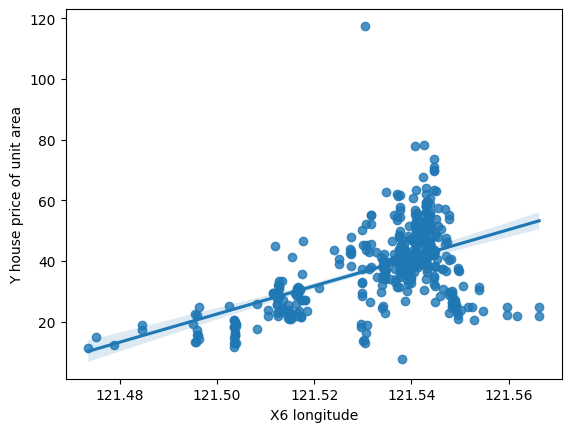

In [1194]:
for i in df.columns[:-1]:
  sns.regplot(data=df, x=i, y=df.columns[-1])
  plt.show()

#Separate X and y

In [1195]:
x = df.iloc[:,:-1]
y=df.iloc[:,-1]

In [1196]:
x

,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude
0,32.0,84.87882,10,24.98298,121.54024
1,19.5,306.59470,9,24.98034,121.53951
2,13.3,561.98450,5,24.98746,121.54391
3,13.3,561.98450,5,24.98746,121.54391
4,5.0,390.56840,5,24.97937,121.54245
...,...,...,...,...,...
409,13.7,4082.01500,0,24.94155,121.50381
410,5.6,90.45606,9,24.97433,121.54310
411,18.8,390.96960,7,24.97923,121.53986
412,8.1,104.81010,5,24.96674,121.54067


In [1197]:
y

,Y house price of unit area
0,37.9
1,42.2
2,47.3
3,54.8
4,43.1
...,...
409,15.4
410,50.0
411,40.6
412,52.5


# Train Test Split Data

In [1198]:
from numpy.random.mtrand import random
x_train,x_test,y_train,y_test = train_test_split(x,y,train_size=.2,random_state=42)

# Scaling Data

In [1199]:
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [1200]:
x_train

array([[0.45953003, 0.38541924, 0.2       , 0.7950209 , 0.35977417],
       [0.47519582, 0.46749074, 0.3       , 0.36380156, 0.24135498],
       [0.10182768, 0.        , 0.8       , 0.27966564, 0.5947777 ],
       [0.82767624, 0.24358462, 0.        , 0.12047974, 0.49061397],
       [0.42819843, 0.05260297, 0.5       , 0.70979466, 0.67833451],
       [0.97389034, 0.11813351, 0.8       , 0.50517899, 0.71870148],
       [1.        , 0.08561061, 0.        , 0.52044339, 0.54777699],
       [0.45953003, 0.17296906, 0.        , 0.37016173, 0.73747354],
       [0.34203655, 0.1124481 , 0.5       , 0.80846811, 0.68440367],
       [0.50130548, 0.12439166, 0.3       , 0.62256951, 0.59633028],
       [0.89817232, 0.10164994, 0.6       , 0.80883155, 0.67170078],
       [0.7310705 , 0.07088607, 0.6       , 0.6434672 , 0.6460127 ],
       [0.92167102, 0.12442965, 0.8       , 0.66291114, 0.57868737],
       [0.79112272, 0.26669129, 0.        , 0.10648737, 0.4815808 ],
       [0.46214099, 0.17296906, 0.

# Model BUilding

In [1201]:
model = DecisionTreeRegressor(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

model.fit(x_train, y_train)

DecisionTreeRegressor(max_depth=5, min_samples_leaf=5, min_samples_split=10,
                      random_state=42)

In [1202]:
y_pred = model.predict(x_test)
y_pred

array([59.3       , 40.38181818, 48.48      , 40.38181818, 22.3       ,
       43.3       , 49.38      , 49.38      , 16.7125    , 67.6       ,
       22.3       , 26.3       , 26.3       , 16.7125    , 25.62      ,
       22.3       , 40.38181818, 48.48      , 22.3       , 40.38181818,
       16.7125    , 22.3       , 59.3       , 40.38181818, 16.7125    ,
       43.3       , 16.7125    , 48.48      , 36.78      , 44.7       ,
       16.7125    , 26.3       , 40.38181818, 16.7125    , 43.3       ,
       36.78      , 59.3       , 16.7125    , 43.3       , 36.78      ,
       44.7       , 40.1       , 44.7       , 40.1       , 40.38181818,
       67.6       , 40.38181818, 25.62      , 59.3       , 44.7       ,
       59.3       , 59.3       , 40.1       , 40.38181818, 40.38181818,
       16.7125    , 36.78      , 25.62      , 22.3       , 49.38      ,
       26.3       , 22.3       , 16.7125    , 16.7125    , 22.3       ,
       22.3       , 16.7125    , 40.38181818, 40.1       , 16.71

# Evaluation

In [1203]:
r2 = r2_score(y_test,y_pred)
mape = mean_absolute_percentage_error(y_test,y_pred)

In [1204]:
print("R2 Score : ",r2)
print("MAPE : ",mape)

R2 Score :  0.43012228954834086
MAPE :  0.20108035816202519


#Feature Extraction (study)

In [1205]:
df2 = pd.DataFrame({'date': ['2005-01-25']})

In [1206]:
df2['date'] = pd.to_datetime(df2['date'])

In [1207]:
df2.dtypes

,0
date,datetime64[ns]


In [1208]:
df2['year'] = df2['date'].dt.year

In [1209]:
df2['month'] = df2['date'].dt.month

In [1210]:
df2['day'] = df2['date'].dt.day

In [1211]:
df2

,date,year,month,day
0,2005-01-25,2005,1,25


'.///